In [ ]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [16]:
dataFrames = {}
for elemento in os.listdir("."):
    if elemento.endswith(".csv"):
        dataFrames[elemento[:-4]] = pd.read_csv(elemento)
dataFrames.keys()

dict_keys(['event', 'fight', 'fighter', 'fighter_bonus', 'master', 'round', 'scrape_error'])

In [178]:
eventsDf = dataFrames["event"]
fightDf = dataFrames["fight"]
fighterDf = dataFrames["fighter"]
fighterBonusDf = dataFrames["fighter_bonus"]
masterDf = dataFrames["master"]
roundDf = dataFrames["round"]
scrapeErrorDf = dataFrames["scrape_error"]

In [ ]:
eventsDf.head(2)

,event_id,event_name,date,location
0,495add4fbede0a44,UFC Fight Night: Gamrot vs. Salkilld,2026-08-08,"Las Vegas, Nevada, USA"
1,1a50e734bb54861a,UFC Fight Night: Medic vs. Rodriguez,2026-08-01,"Belgrade, Vojvodina, Serbia"


In [50]:
fightDf.columns

Index(['event_id', 'fight_id', 'weight_class', 'title_fight', 'r_id', 'b_id',
       'winner_id', 'result_status', 'method', 'round', 'time', 'time_format',
       'referee', 'details'],
      dtype='str')

In [ ]:
peleasConFinalizaciones = fightDf[
    fightDf["method"].isin(["KO/TKO", "Submission", "TKO - Doctor's Stoppage"])
]
peleasConFinalizaciones.groupby("method")["fight_id"].count()

method
KO/TKO                     3715
Submission                 2411
TKO - Doctor's Stoppage     152
Name: fight_id, dtype: int64

In [85]:
peleasPorRoundFinalizadas = fightDf.groupby("method")["r_id"].count()
peleasPorRoundFinalizadas

method
Could Not Continue           48
DQ                           35
Decision                      3
Decision - Majority         117
Decision - Split           1015
Decision - Unanimous       3860
KO/TKO                     3715
Other                        14
Overturned                   71
Submission                 2411
TKO - Doctor's Stoppage     152
Name: r_id, dtype: int64

In [ ]:
peleas_con_bonos = masterDf[masterDf["bonuses"].notna()]
peleas_agrupadas_por_bonos = peleas_con_bonos.groupby("")["fight_id"].count()
cantidad_bonos = dict(peleas_agrupadas_por_bonos)
cantidad_bonos

{'Fight of the Night': np.int64(580),
 'Fight of the Night, Knockout of the Night': np.int64(12),
 'Fight of the Night, Performance of the Night': np.int64(29),
 'Fight of the Night, Submission of the Night': np.int64(17),
 'Knockout of the Night': np.int64(208),
 'Performance of the Night': np.int64(1313),
 'Submission of the Night': np.int64(192)}

In [ ]:
peleas = masterDf[masterDf["result_status"] == "win"].copy()
peleas["event_date"] = pd.to_datetime(peleas["event_date"])

# Separamos a los peleadores
rojo = peleas[["event_date", "r_dob", "r_fighter_id", "winner_id"]].copy()
rojo.columns = ["fecha", "fecha_nacimiento", "peleador", "ganador"]

azul = peleas[["event_date", "b_dob", "b_fighter_id", "winner_id"]].copy()
azul.columns = ["fecha", "fecha_nacimiento", "peleador", "ganador"]

df = pd.concat([rojo, azul])

# Edad el día de la pelea y si perdió
df["fecha_nacimiento"] = pd.to_datetime(df["fecha_nacimiento"])
df["edad"] = (
    df["fecha"] - df["fecha_nacimiento"]
).dt.days / 365.25  # Duración aproximada de un año, en días segun google
df = df.dropna(subset=["edad"])
df["edad"] = df["edad"].astype(int)
df["perdio"] = df["peleador"] != df["ganador"]

derrotas = df.groupby("edad")["perdio"].agg(["mean", "count"])
derrotas = derrotas[derrotas["count"] >= 100]
derrotas["pct"] = derrotas["mean"] * 100
# derrotas_25_35 = derrotas[derrotas["edad"].between(25, 35)]
# derrotas_25_35
derrotas

,mean,count,pct
edad,,,
21,0.416244,197,41.624365
22,0.404700,383,40.469974
23,0.413793,696,41.379310
24,0.436422,928,43.642241
25,0.453292,1306,45.329250
26,0.448941,1606,44.894147
27,0.435127,1896,43.512658
28,0.467069,1989,46.706888
29,0.489404,2029,48.940365


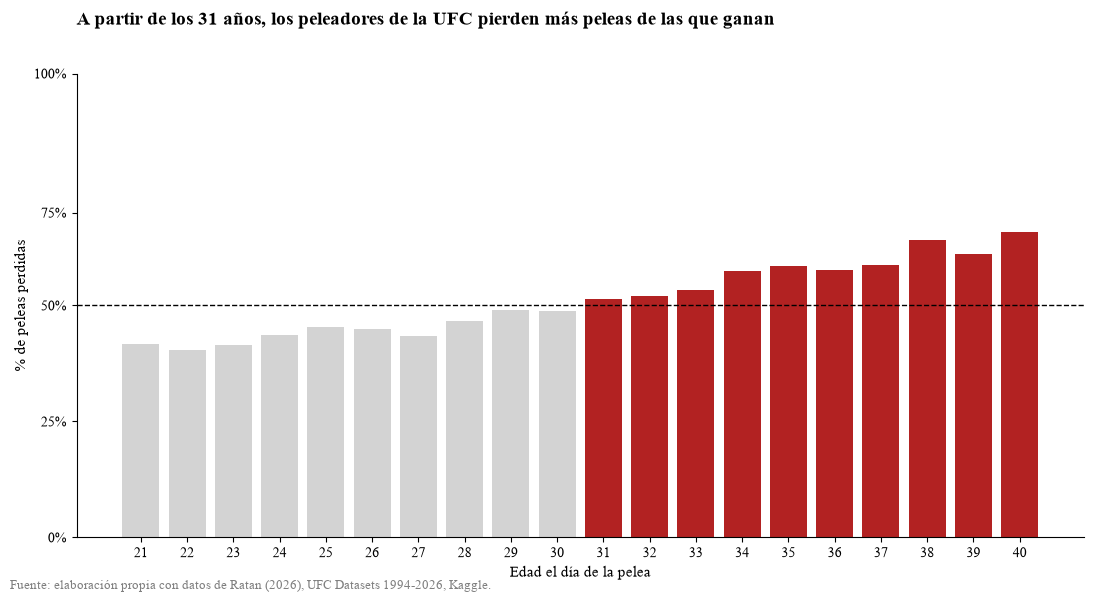

In [238]:
# Gráfico
colores = ["firebrick" if x > 50 else "lightgray" for x in derrotas["pct"]]

LABEL_FONT = 11
font = "Times New Roman"

plt.rcParams["font.family"] = font
plt.figure(figsize=(11, 6))
plt.bar(derrotas.index, derrotas["pct"], color=colores)
plt.axhline(50, color="black", linestyle="--", linewidth=1)
# plt.text(20.6, 51, "50%: pierde tantas peleas como gana", fontsize=10)
"""
for edad in [21, 31, 40]:
    valor = derrotas.loc[edad, "pct"]
    plt.text(edad, valor + 1, f"{valor:.0f}%", ha="center", fontweight="bold")
"""

plt.title(
    "A partir de los 31 años, los peleadores de la UFC pierden más peleas de las que ganan\n\n",
    fontsize=14,
    fontweight="bold",
    loc="left",
)
plt.xlabel("Edad el día de la pelea", fontsize=LABEL_FONT)
plt.ylabel("% de peleas perdidas", fontsize=LABEL_FONT)
plt.xticks(derrotas.index)
plt.ylim(0, 100)
plt.yticks([0, 25, 50, 70, 100], ["0%", "25%", "50%", "75%", "100%"])
plt.gca().spines[["top", "right"]].set_visible(False)
plt.figtext(
    0.01,
    0.01,
    "Fuente: elaboración propia con datos de Ratan (2026), UFC Datasets 1994-2026, Kaggle.",
    fontsize=9,
    color="gray",
)

plt.tight_layout()
plt.savefig("derrotas_por_edad.png", dpi=300)
plt.show()

In [220]:
def a_cm(altura):
    if pd.isna(altura):
        return np.nan
    pies, pulgadas = altura.replace('"', "").split("'")
    return int(pies) * 30.48 + int(pulgadas) * 2.54


# Solo peleas con ganador
peleas = masterDf[masterDf["result_status"] == "win"].copy()
peleas["r_cm"] = peleas["r_height"].apply(a_cm)
peleas["b_cm"] = peleas["b_height"].apply(a_cm)
peleas = peleas.dropna(subset=["r_cm", "b_cm"])

# Cada pelea vista desde los dos peleadores: diferencia de altura y si ganó
rojo = pd.DataFrame(
    {
        "dif_cm": peleas["r_cm"] - peleas["b_cm"],
        "gano": peleas["winner_id"] == peleas["r_fighter_id"],
    }
)
azul = pd.DataFrame(
    {
        "dif_cm": peleas["b_cm"] - peleas["r_cm"],
        "gano": peleas["winner_id"] == peleas["b_fighter_id"],
    }
)
df = pd.concat([rojo, azul])
df["dif_cm"] = df["dif_cm"].round(1)
df = df[df["dif_cm"] >= 0]
# % de victorias por cada diferencia de altura (solo con al menos 100 peleas)
resultado = df.groupby("dif_cm")["gano"].agg(["mean", "count"])
resultado = resultado[resultado["count"] >= 100]
resultado["pct"] = resultado["mean"] * 100
print(resultado)

# Regresión lineal
x = resultado.index
y = resultado["pct"]
pendiente, intercepto = np.polyfit(x, y, 1)
r2 = np.corrcoef(x, y)[0, 1] ** 2
print(f"Pendiente: {pendiente:.2f} puntos de % por cada cm")
print(f"Con 10 cm de ventaja: {intercepto + pendiente * 10:.1f}% de victorias")
print(f"R² con los promedios: {r2:.2f}")

# R² pelea por pelea: cuánto explica la altura del resultado individual
r2_individual = np.corrcoef(df["dif_cm"], df["gano"])[0, 1] ** 2

            mean  count        pct
dif_cm                            
0.0     0.500000   3680  50.000000
2.5     0.511476   3224  51.147643
5.1     0.512778   2426  51.277824
7.6     0.529340   1636  52.933985
10.2    0.556557    999  55.655656
12.7    0.530452    509  53.045187
15.2    0.518692    214  51.869159
Pendiente: 0.19 puntos de % por cada cm
Con 10 cm de ventaja: 52.7% de victorias
R² con los promedios: 0.34


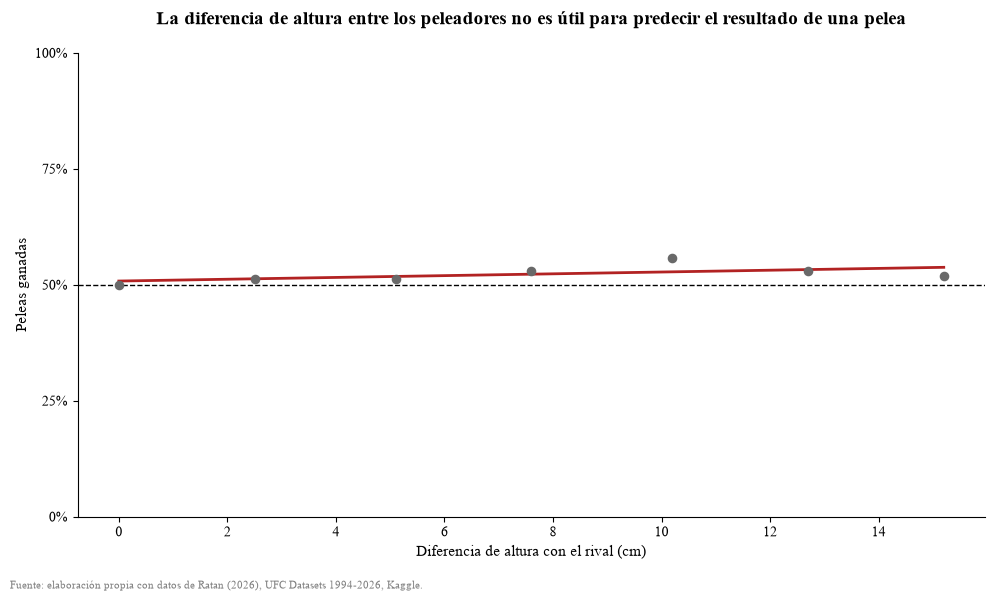

In [237]:
# Gráfico

LABEL_FONT = 11
font = "Times New Roman"

plt.rcParams["font.family"] = font
plt.figure(figsize=(10, 6))
plt.scatter(x, y, color="dimgray", s=35, zorder=3)
plt.plot(x, intercepto + pendiente * x, color="firebrick", linewidth=2)
plt.axhline(50, color="black", linestyle="--", linewidth=1)

plt.title(
    "La diferencia de altura entre los peleadores no es útil para predecir el resultado de una pelea\n",
    fontsize=14,
    fontweight="bold",
    loc="center",
)
plt.xlabel("Diferencia de altura con el rival (cm)", fontsize=LABEL_FONT)
plt.ylabel("Peleas ganadas", fontsize=LABEL_FONT)
plt.ylim(0, 100)
plt.yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
# plt.grid(axis='x', color='lightgray', linewidth=0.8)
plt.gca().set_axisbelow(True)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.figtext(
    0.01,
    0.01,
    "Fuente: elaboración propia con datos de Ratan (2026), UFC Datasets 1994-2026, Kaggle.",
    fontsize=8,
    color="gray",
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.13)
plt.savefig("altura_victorias.png", dpi=300)
plt.show()